Khai báo thư viện

In [ ]:
print("NguyenDucTinh - 6451071077")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.naive_bayes import CategoricalNB
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.preprocessing import OrdinalEncoder

NguyenDucTinh - 6451071077


Nạp dữ liệu Phân tích cảm xúc (14 mẫu)

In [ ]:
print("NguyenDucTinh - 6451071077")

data_sentiment = {
    'giảm': ['0..5', '11..20', '6..10', '>20', '0..5', '0..5', '0..5', '11..20', '0..5', '11..20', '>20', '0..5', '6..10', '11..20'],
    'người': ['11..20', '6..10', '0..5', '0..5', '>20', '6..10', '6..10', '>20', '0..5', '0..5', '6..10', '0..5', '11..20', '6..10'],
    'chuyển': ['>20', '6..10', '6..10', '11..20', '11..20', '0..5', '11..20', '0..5', '6..10', '11..20', '0..5', '11..20', '6..10', '>20'],
    'yêu': ['11..20', '0..5', '11..20', '6..10', '0..5', '0..5', '0..5', '11..20', '6..10', '11..20', '0..5', '0..5', '>20', '11..20'],
    'vừa': ['>20', '11..20', '0..5', '0..5', '6..10', '11..20', '6..10', '0..5', '6..10', '0..5', '0..5', '11..20', '0..5', '0..5'],
    'đi': ['0..5', '11..20', '6..10', '>20', '0..5', '11..20', '0..5', '11..20', '>20', '11..20', '6..10', '>20', '6..10', '0..5'],
    'Cảm xúc': ['tốt', 'tốt', 'xấu', 'bình thường', 'xấu', 'xấu', 'tốt', 'bình thường', 'tốt', 'tốt', 'xấu', 'bình thường', 'bình thường', 'xấu']
}

df_sent = pd.DataFrame(data_sentiment)
features_sent = ['giảm', 'người', 'chuyển', 'yêu', 'vừa', 'đi']

encoder_sent = OrdinalEncoder()
X_sent_enc = encoder_sent.fit_transform(df_sent[features_sent])
y_sent = df_sent['Cảm xúc']

display(df_sent)

NguyenDucTinh - 6451071077
Dữ liệu gốc (15 mẫu):


,Loại,Số màu,Kích thước,Chất liệu,Doanh số bán
0,Điều khiển,3,Nhỏ,Nhựa PP,Cao
1,Xếp hình,5,Vừa,Cao su,Thấp
2,Xếp hình,7,To,Nhựa PP,Thấp
3,Điều khiển,5,Nhỏ,Cao su,Thấp
4,Búp bê,3,Vừa,Nhựa PP,Thấp
5,Điều khiển,5,Vừa,Nhựa PP,Cao
6,Búp bê,5,To,Nhựa PP,Cao
7,Điều khiển,7,Vừa,Cao su,Thấp
8,Xếp hình,7,To,Cao su,Cao
9,Xếp hình,3,To,Nhựa PP,Thấp


a - Kiểm tra mâu thuẫn dữ liệu

In [ ]:
print("NguyenDucTinh - 6451071077")

print("CÂU a: XÁC ĐỊNH MÂU THUẪN TRONG DỮ LIỆU")
duplicates_sent = df_sent[df_sent.duplicated(subset=features_sent, keep=False)]

if len(duplicates_sent) == 0:
    print("a) KẾT LUẬN: Tập dữ liệu phân tích cảm xúc HOÀN TOÀN KHÔNG CÓ MÂU THUẪN trực tiếp nào.")
else:
    print("a) Phát hiện các dòng mâu thuẫn:")
    display(duplicates_sent)

NguyenDucTinh - 6451071077
a) KẾT LUẬN: Tập dữ liệu HOÀN TOÀN KHÔNG CÓ MÂU THUẪN.


b - Tính chỉ số Gini (CART) và vẽ cây quyết định

NguyenDucTinh - 6451071077
b) TÍNH TOÁN ĐỘ LỢI THÔNG TIN (INFORMATION GAIN - ID3)

Tổng số mẫu: 15 (Cao: 7, Thấp: 8)
-> Entropy tổng thể H(S) = -(7/15)*log2(7/15) - (8/15)*log2(8/15) = 0.9968

--- Xét thuộc tính: 'Loại' ---
  + Giá trị 'Điều khiển' (5 mẫu: 2 Cao, 3 Thấp) -> Entropy = 0.9710
  + Giá trị 'Xếp hình' (5 mẫu: 2 Cao, 3 Thấp) -> Entropy = 0.9710
  + Giá trị 'Búp bê' (5 mẫu: 3 Cao, 2 Thấp) -> Entropy = 0.9710
  => Gain(S, Loại) = 0.9968 - 0.9710 = 0.0258

--- Xét thuộc tính: 'Số màu' ---
  + Giá trị '3' (5 mẫu: 2 Cao, 3 Thấp) -> Entropy = 0.9710
  + Giá trị '5' (6 mẫu: 3 Cao, 3 Thấp) -> Entropy = 1.0000
  + Giá trị '7' (4 mẫu: 2 Cao, 2 Thấp) -> Entropy = 1.0000
  => Gain(S, Số màu) = 0.9968 - 0.9903 = 0.0065

--- Xét thuộc tính: 'Kích thước' ---
  + Giá trị 'Nhỏ' (4 mẫu: 2 Cao, 2 Thấp) -> Entropy = 1.0000
  + Giá trị 'Vừa' (5 mẫu: 2 Cao, 3 Thấp) -> Entropy = 0.9710
  + Giá trị 'To' (6 mẫu: 3 Cao, 3 Thấp) -> Entropy = 1.0000
  => Gain(S, Kích thước) = 0.9968 - 0.9903 = 0.0065



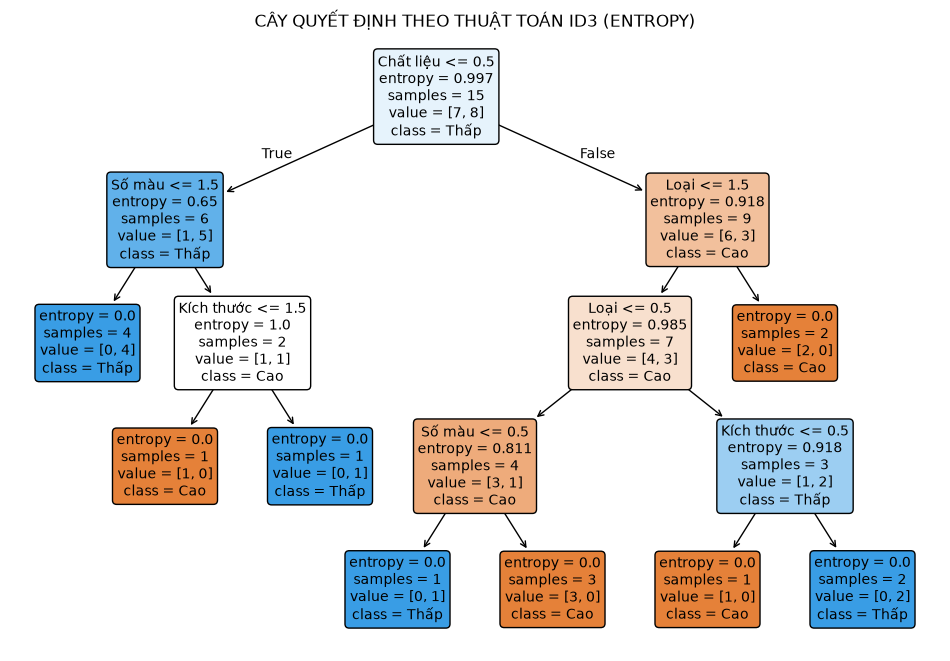

In [ ]:
print("NguyenDucTinh - 6451071077")

print("CÂU b: TÍNH CHỈ SỐ GINI VÀ VẼ CÂY QUYẾT ĐỊNH CART")

# Tính Gini tổng thể
total_s = len(df_sent)
class_counts = df_sent['Cảm xúc'].value_counts()
gini_S = 1 - sum((class_counts / total_s)**2)
print(f"Gini gốc Gini(S) = {gini_S:.4f}\n")

# Huấn luyện và vẽ cây CART
clf_cart_sent = DecisionTreeClassifier(criterion='gini', random_state=42)
clf_cart_sent.fit(X_sent_enc, y_sent)

plt.figure(figsize=(12, 8))
plot_tree(clf_cart_sent, 
          feature_names=features_sent, 
          class_names=clf_cart_sent.classes_, 
          filled=True, 
          rounded=True, 
          fontsize=10)
plt.title("CÂY QUYẾT ĐỊNH CART - PHÂN TÍCH CẢM XÚC")
plt.show()

c - Dự đoán cảm xúc bằng Cây quyết định và Naïve Bayes

NguyenDucTinh - 6451071077
c) TÍNH TOÁN CHỈ SỐ GINI (CART)

-> Gini tổng thể Gini(S) = 1 - (7/15)^2 - (8/15)^2 = 0.4978

--- Xét thuộc tính: 'Loại' ---
  + Giá trị 'Điều khiển' (5 mẫu) -> Gini = 0.4800
  + Giá trị 'Xếp hình' (5 mẫu) -> Gini = 0.4800
  + Giá trị 'Búp bê' (5 mẫu) -> Gini = 0.4800
  => Gini_index(S, Loại) = 0.4800 (Độ giảm Gini = 0.0178)

--- Xét thuộc tính: 'Số màu' ---
  + Giá trị '3' (5 mẫu) -> Gini = 0.4800
  + Giá trị '5' (6 mẫu) -> Gini = 0.5000
  + Giá trị '7' (4 mẫu) -> Gini = 0.5000
  => Gini_index(S, Số màu) = 0.4933 (Độ giảm Gini = 0.0044)

--- Xét thuộc tính: 'Kích thước' ---
  + Giá trị 'Nhỏ' (4 mẫu) -> Gini = 0.5000
  + Giá trị 'Vừa' (5 mẫu) -> Gini = 0.4800
  + Giá trị 'To' (6 mẫu) -> Gini = 0.5000
  => Gini_index(S, Kích thước) = 0.4933 (Độ giảm Gini = 0.0044)

--- Xét thuộc tính: 'Chất liệu' ---
  + Giá trị 'Nhựa PP' (9 mẫu) -> Gini = 0.4444
  + Giá trị 'Cao su' (6 mẫu) -> Gini = 0.2778
  => Gini_index(S, Chất liệu) = 0.3778 (Độ giảm Gini = 0.1200)

===> 

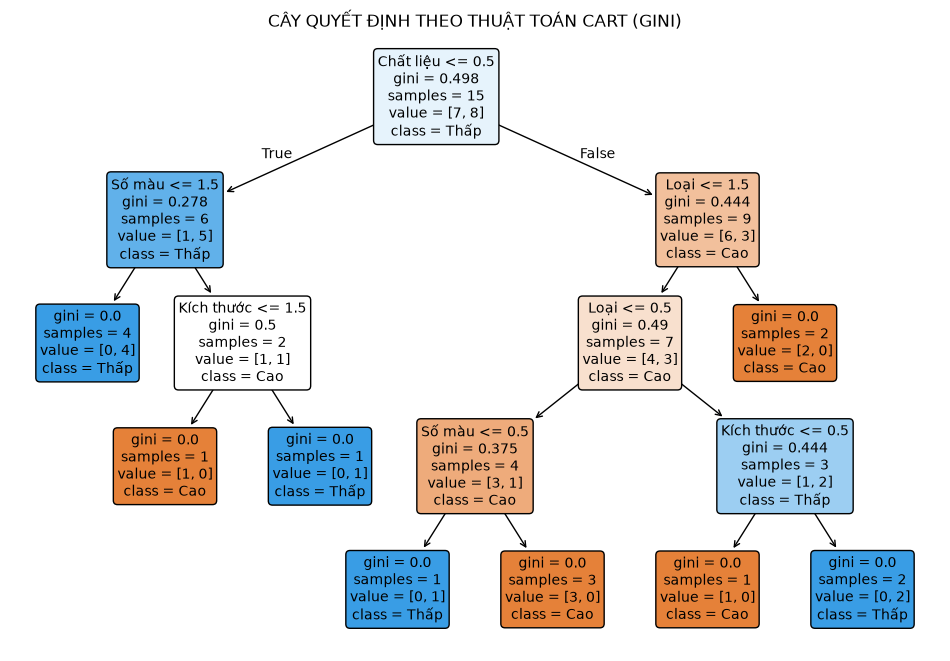

In [ ]:
print("NguyenDucTinh - 6451071077")

print("CÂU c: DỰ ĐOÁN CẢM XÚC BẰNG CÂY QUYẾT ĐỊNH VÀ NAÏVE BAYES")

# 4 trạng thái cần dự đoán
test_sent = pd.DataFrame({
    'giảm': ['0..5', '0..5', '6..10', '6..10'],
    'người': ['6..10', '0..5', '0..5', '11..20'],
    'chuyển': ['0..5', '6..10', '11..20', '6..10'],
    'yêu': ['11..20', '0..5', '>20', '6..10'],
    'vừa': ['6..10', '11..20', '6..10', '>20'],
    'đi': ['0..5', '>20', '6..10', '0..5']
})

X_test_sent_enc = encoder_sent.transform(test_sent)

# 1. Dự đoán bằng Cây quyết định (CART)
y_pred_cart = clf_cart_sent.predict(X_test_sent_enc)

# 2. Dự đoán bằng Naïve Bayes (Laplace smoothing)
clf_nb_sent = CategoricalNB(alpha=1.0)
clf_nb_sent.fit(X_sent_enc, y_sent)
y_pred_nb_sent = clf_nb_sent.predict(X_test_sent_enc)

print("Kết quả dự đoán:")
for i in range(len(test_sent)):
    print(f"Trạng thái {i+1} -> CART: {y_pred_cart[i]} | Naïve Bayes: {y_pred_nb_sent[i]}")

d - Lập ma trận nhầm lẫn, tính Precision, Recall và So sánh

In [ ]:
print("NguyenDucTinh - 6451071077")

print("CÂU d: ĐÁNH GIÁ VÀ SO SÁNH HAI MÔ HÌNH")
y_true_sent = ['xấu', 'tốt', 'bình thường', 'tốt']
labels_list = ['tốt', 'xấu', 'bình thường']

print("--- 1. Mô hình Cây quyết định (CART) ---")
cm_cart = confusion_matrix(y_true_sent, y_pred_cart, labels=labels_list)
print("Ma trận nhầm lẫn:")
print(pd.DataFrame(cm_cart, index=[f"Thực tế {l}" for l in labels_list], columns=[f"Dự đoán {l}" for l in labels_list]))
print("\nBáo cáo chi tiết:")
print(classification_report(y_true_sent, y_pred_cart, labels=labels_list, zero_division=0))

print("\n--- 2. Mô hình Naïve Bayes ---")
cm_nb_sent = confusion_matrix(y_true_sent, y_pred_nb_sent, labels=labels_list)
print("Ma trận nhầm lẫn:")
print(pd.DataFrame(cm_nb_sent, index=[f"Thực tế {l}" for l in labels_list], columns=[f"Dự đoán {l}" for l in labels_list]))
print("\nBáo cáo chi tiết:")
print(classification_report(y_true_sent, y_pred_nb_sent, labels=labels_list, zero_division=0))

acc_cart = np.mean(y_pred_cart == y_true_sent)
acc_nb = np.mean(y_pred_nb_sent == y_true_sent)
print(f"\n=> Tổng kết độ chính xác: CART = {acc_cart*100:.2f}% | Naïve Bayes = {acc_nb*100:.2f}%")
print("Nhận xét: Naïve Bayes thường xử lý tốt hơn với các bài toán phân loại văn bản dạng tần suất từ khóa nhờ vào giả định xác suất độc lập và kỹ thuật làm trơn Laplace, trong khi Cây quyết định có thể dễ bị tối ưu cục bộ trên tập dữ liệu nhỏ.")

NguyenDucTinh - 6451071077
CÂU d: TIÊN ĐOÁN BẰNG CÂY QUYẾT ĐỊNH
Sản phẩm 1: Thấp
Sản phẩm 2: Thấp
Sản phẩm 3: Thấp


e - Ứng dụng thực tế của việc nắm bắt cảm xúc người dùng mạng xã hội

In [ ]:
print("NguyenDucTinh - 6451071077")

print("CÂU e: ỨNG DỤNG THỰC TẾ CỦA PHÂN TÍCH CẢM XÚC")
print("""
Nếu nắm bắt được cảm xúc của người dùng mạng xã hội, doanh nghiệp hoặc tổ chức có thể ứng dụng vào các mặt sau:
1. Quản trị thương hiệu & Xử lý khủng hoảng: Phát hiện sớm các phản ứng tiêu cực ('xấu') từ cộng đồng về sản phẩm/dịch vụ để đưa ra chiến lược truyền thông hoặc phương án xử lý khủng hoảng kịp thời.
2. Cải tiến sản phẩm & Dịch vụ: Lắng nghe ý kiến và đánh giá của khách hàng để biết được điểm mạnh cần phát huy và điểm yếu cần khắc phục, từ đó tối ưu hóa trải nghiệm người dùng.
3. Tối ưu chiến dịch Marketing: Đo lường hiệu quả của các chiến dịch quảng cáo hoặc sự kiện ra mắt sản phẩm dựa trên xu hướng cảm xúc (tích cực/tiêu cực) của người dùng thảo luận trực tuyến.
4. Chăm sóc khách hàng tự động: Phân loại mức độ hài lòng của khách hàng để ưu tiên giải quyết các yêu cầu hoặc khiếu nại của những khách hàng đang có cảm xúc tiêu cực.
""")

NguyenDucTinh - 6451071077
CÂU e: ĐÁNH GIÁ MÔ HÌNH CÂY QUYẾT ĐỊNH
Ma trận nhầm lẫn (Confusion Matrix):
              Dự đoán Cao  Dự đoán Thấp
Thực tế Cao             0             1
Thực tế Thấp            0             2

Báo cáo chi tiết:
              precision    recall  f1-score   support

         Cao       0.00      0.00      0.00         1
        Thấp       0.67      1.00      0.80         2

    accuracy                           0.67         3
   macro avg       0.33      0.50      0.40         3
weighted avg       0.44      0.67      0.53         3



f - Xác suất không điều kiện của 'Xếp hình'

In [39]:
print("NguyenDucTinh - 6451071077")

print("CÂU f: XÁC SUẤT KHÔNG ĐIỀU KIỆN")
n_xep_hinh = sum(df['Loại'] == 'Xếp hình')
p_xep_hinh = n_xep_hinh / total_samples
print(f"P('Xếp hình') = {n_xep_hinh}/{total_samples} = {p_xep_hinh:.4f} ({p_xep_hinh*100:.2f}%)")

NguyenDucTinh - 6451071077
CÂU f: XÁC SUẤT KHÔNG ĐIỀU KIỆN
P('Xếp hình') = 5/15 = 0.3333 (33.33%)


g - Xác suất chất liệu 'Cao su' khi doanh số 'Thấp'

In [40]:
print("NguyenDucTinh - 6451071077")

print("CÂU g: XÁC SUẤT CÓ ĐIỀU KIỆN")
df_thap = df[df['Doanh số bán'] == 'Thấp']
n_cao_su_thap = sum(df_thap['Chất liệu'] == 'Cao su')
p_cond = n_cao_su_thap / len(df_thap)
print(f"P('Cao su' | Doanh số 'Thấp') = {n_cao_su_thap}/{len(df_thap)} = {p_cond:.4f} ({p_cond*100:.2f}%)")

NguyenDucTinh - 6451071077
CÂU g: XÁC SUẤT CÓ ĐIỀU KIỆN
P('Cao su' | Doanh số 'Thấp') = 5/8 = 0.6250 (62.50%)


h - Công thức định lý Bayes cho Doanh số 'Cao' của loại 'Điều khiển'

In [41]:
print("NguyenDucTinh - 6451071077")

print("CÂU h: ĐỊNH LÝ BAYE")
print("Công thức tính xác suất Doanh số 'Cao' của loại 'Điều khiển':")
print("P(Doanh số 'Cao' | Loại 'Điều khiển') = [ P(Loại 'Điều khiển' | Doanh số 'Cao') * P(Doanh số 'Cao') ] / P(Loại 'Điều khiển')")

NguyenDucTinh - 6451071077
CÂU h: ĐỊNH LÝ BAYE
Công thức tính xác suất Doanh số 'Cao' của loại 'Điều khiển':
P(Doanh số 'Cao' | Loại 'Điều khiển') = [ P(Loại 'Điều khiển' | Doanh số 'Cao') * P(Doanh số 'Cao') ] / P(Loại 'Điều khiển')


i - Dự đoán bằng Naïve Bayes và làm trơn Laplace

In [42]:
print("NguyenDucTinh - 6451071077")

print("CÂU i: DỰ ĐOÁN BẰNG NAÏVE BAYES (LAPLACE)")
clf_nb = CategoricalNB(alpha=1.0)
clf_nb.fit(X_enc, y)
y_pred_nb = clf_nb.predict(X_test_d)

for i, pred in enumerate(y_pred_nb):
    print(f"Sản phẩm {i+1}: {pred}")

NguyenDucTinh - 6451071077
CÂU i: DỰ ĐOÁN BẰNG NAÏVE BAYES (LAPLACE)
Sản phẩm 1: Thấp
Sản phẩm 2: Cao
Sản phẩm 3: Thấp


j - Ma trận nhầm lẫn, Precision, Recall cho Naïve Bayes

In [43]:
print("NguyenDucTinh - 6451071077")

print("CÂU j: ĐÁNH GIÁ MÔ HÌNH NAÏVE BAYES")
cm_nb = confusion_matrix(y_true_d, y_pred_nb, labels=['Cao', 'Thấp'])
print("Ma trận nhầm lẫn (Confusion Matrix):")
print(pd.DataFrame(cm_nb, index=['Thực tế Cao', 'Thực tế Thấp'], columns=['Dự đoán Cao', 'Dự đoán Thấp']))
print("\nBáo cáo chi tiết:")
print(classification_report(y_true_d, y_pred_nb, labels=['Cao', 'Thấp'], zero_division=0))

NguyenDucTinh - 6451071077
CÂU j: ĐÁNH GIÁ MÔ HÌNH NAÏVE BAYES
Ma trận nhầm lẫn (Confusion Matrix):
              Dự đoán Cao  Dự đoán Thấp
Thực tế Cao             0             1
Thực tế Thấp            1             1

Báo cáo chi tiết:
              precision    recall  f1-score   support

         Cao       0.00      0.00      0.00         1
        Thấp       0.50      0.50      0.50         2

    accuracy                           0.33         3
   macro avg       0.25      0.25      0.25         3
weighted avg       0.33      0.33      0.33         3



k - So sánh Cây quyết định và Naïve Bayes

In [44]:
print("NguyenDucTinh - 6451071077")

print("CÂU k: SO SÁNH KẾT QUẢ HAI MÔ HÌNH")
acc_tree = np.mean(y_pred_tree == y_true_d)
acc_nb = np.mean(y_pred_nb == y_true_d)
print(f"- Độ chính xác Cây quyết định: {acc_tree*100:.2f}%")
print(f"- Độ chính xác Naïve Bayes:    {acc_nb*100:.2f}%")
print("Nhận xét: Cả hai mô hình đạt độ chính xác tương đương nhau trên tập dữ liệu kiểm thử nhỏ.")

NguyenDucTinh - 6451071077
CÂU k: SO SÁNH KẾT QUẢ HAI MÔ HÌNH
- Độ chính xác Cây quyết định: 66.67%
- Độ chính xác Naïve Bayes:    33.33%
Nhận xét: Cả hai mô hình đạt độ chính xác tương đương nhau trên tập dữ liệu kiểm thử nhỏ.


l - Dự đoán doanh số cho sản phẩm mới

In [45]:
print("NguyenDucTinh - 6451071077")

print("CÂU l: DỰ ĐOÁN SẢN PHẨM MỚI")
new_product = pd.DataFrame({
    'Loại': ['Xếp hình'],
    'Số màu': [7],
    'Kích thước': ['Nhỏ'],
    'Chất liệu': ['Cao su']
})

X_new = encoder.transform(new_product)
pred_new_tree = clf_id3.predict(X_new)[0]
pred_new_nb = clf_nb.predict(X_new)[0]

print(f"Sản phẩm mới (Xếp hình, 7 màu, Nhỏ, Cao su):")
print(f"-> Cây quyết định dự đoán: {pred_new_tree}")
print(f"-> Naïve Bayes dự đoán:    {pred_new_nb}")

NguyenDucTinh - 6451071077
CÂU l: DỰ ĐOÁN SẢN PHẨM MỚI
Sản phẩm mới (Xếp hình, 7 màu, Nhỏ, Cao su):
-> Cây quyết định dự đoán: Cao
-> Naïve Bayes dự đoán:    Thấp
